# Homework 5

Viraj Dua

GitHub: VirajD24

DSCI 552: Machine Learning

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from xgboost import XGBRegressor

plt.style.use('default')
sns.set_theme(style = "whitegrid", context = "notebook")
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_rows", None)
SEED = 42

## 1. Decision trees as interpretable models

### (a) Load the data

I use the given [Acute Inflammations data](https://archive.ics.uci.edu/dataset/184/acute+inflammations). The 2 diagnoses are combined into four classes: neither, nephritis only, bladder inflammation only, or both. This is the label-powerset approach that's mentioned in the hw5 document.

In [2]:
symptoms = ["Temperature", "Nausea", "LumbarPain", "UrinePushing", "MicturitionPain", "Burning"]
acute = pd.read_csv("diagnosis.data", sep = "\t", encoding = "utf-16", decimal = ",", header = None, names = symptoms + ["Bladder", "Nephritis"])
for column in acute.columns[1:]:
    acute[column] = acute[column].map({"no": 0, "yes": 1})

X_tree = acute[symptoms]
y_tree = 2 * acute["Bladder"] + acute["Nephritis"]
class_names = ["Neither", "Nephritis only", "Bladder only", "Both"]
print(f"{len(acute)} observations, {X_tree.shape[1]} predictors; binary symptoms: no = 0, yes = 1")
display(y_tree.value_counts().sort_index().rename(index = dict(enumerate(class_names))).to_frame("Count").T)

120 observations, 6 predictors; binary symptoms: no = 0, yes = 1


,Neither,Nephritis only,Bladder only,Both
Count,30,31,40,19


### (b) Fit and plot the full tree

I fit the tree to all 120 observations. Its reported accuracy is training accuracy, not an estimate of performance on new patients.

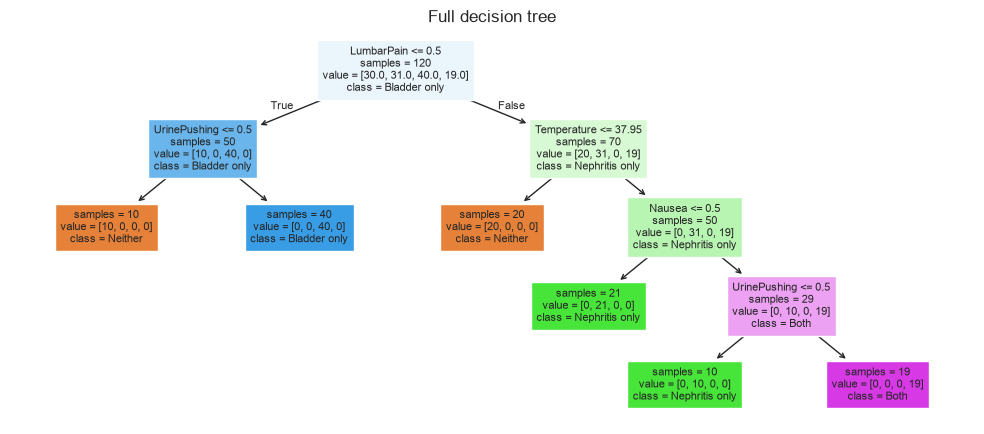

Depth: 4, leaves: 6, training accuracy: 1.0000


In [3]:
full_tree = DecisionTreeClassifier(random_state = SEED).fit(X_tree, y_tree)
plt.figure(figsize = (10, 4.5))
plot_tree(full_tree, feature_names = symptoms, class_names = class_names, filled = True, impurity = False, precision = 2, fontsize = 8)
plt.title("Full decision tree")
plt.tight_layout()
plt.show()
print(f"Depth: {full_tree.get_depth()}, leaves: {full_tree.get_n_leaves()}, "
      f"training accuracy: {full_tree.score(X_tree, y_tree):.4f}")

### (c) IF–THEN rules

Each path from the root to a leaf gives one rule. For binary symptoms, the split at 0.5 means no versus yes.

In [4]:
def decision_rules(model):
    rules = []
    def visit(node, conditions):
        tree = model.tree_
        if tree.children_left[node] == tree.children_right[node]:
            label = model.classes_[tree.value[node][0].argmax()]
            rules.append({"IF": " AND ".join(conditions), "THEN": class_names[label]})
            return
        feature = symptoms[tree.feature[node]]
        threshold = tree.threshold[node]
        left = f"{feature} <= {threshold:.2f}" if feature == "Temperature" else f"{feature}=no"
        right = f"{feature} > {threshold:.2f}" if feature == "Temperature" else f"{feature}=yes"
        visit(tree.children_left[node], conditions + [left])
        visit(tree.children_right[node], conditions + [right])
    visit(0, [])
    return pd.DataFrame(rules)

display(decision_rules(full_tree))

,IF,THEN
0,LumbarPain=no AND UrinePushing=no,Neither
1,LumbarPain=no AND UrinePushing=yes,Bladder only
2,LumbarPain=yes AND Temperature <= 37.95,Neither
3,LumbarPain=yes AND Temperature > 37.95 AND Nausea=no,Nephritis only
4,LumbarPain=yes AND Temperature > 37.95 AND Nausea=yes AND UrinePushing=no,Nephritis only
5,LumbarPain=yes AND Temperature > 37.95 AND Nausea=yes AND UrinePushing=yes,Both


### (d) Cost-complexity pruning

I evaluate the subtrees on the cost-complexity pruning path using five-fold stratified CV; then show the best-scoring genuinely smaller subtree to compare its shorter rules with the full tree. The table includes the unpruned tree, so any loss of accuracy is visible.

,alpha,Leaves,Depth,CV accuracy,Training accuracy
0,0.0000,6,4,0.9917,1.0000
1,0.0982,4,2,0.8583,0.8417
2,0.1333,3,2,0.7583,0.7583
3,0.1820,2,1,0.6667,0.5917
4,0.2229,1,0,0.4833,0.3333


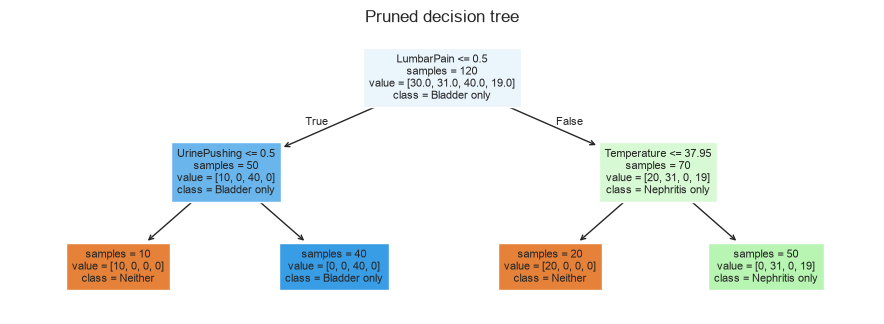

,IF,THEN
0,LumbarPain=no AND UrinePushing=no,Neither
1,LumbarPain=no AND UrinePushing=yes,Bladder only
2,LumbarPain=yes AND Temperature <= 37.95,Neither
3,LumbarPain=yes AND Temperature > 37.95,Nephritis only


In [5]:
tree_cv = StratifiedKFold(5, shuffle = True, random_state = SEED)
alphas = full_tree.cost_complexity_pruning_path(X_tree, y_tree).ccp_alphas
pruning_rows = []

for alpha in alphas:
    model = DecisionTreeClassifier(ccp_alpha = alpha, random_state = SEED)
    cv_accuracy = cross_val_score(model, X_tree, y_tree, cv=tree_cv).mean()
    model.fit(X_tree, y_tree)
    pruning_rows.append({"alpha": alpha, "Leaves": model.get_n_leaves(),
                         "Depth": model.get_depth(), "CV accuracy": cv_accuracy,
                         "Training accuracy": model.score(X_tree, y_tree)})
pruning = pd.DataFrame(pruning_rows)
display(pruning)

smaller = pruning[pruning["Leaves"] < full_tree.get_n_leaves()]
chosen = smaller.sort_values(["CV accuracy", "Leaves"], ascending=[False, True]).iloc[0]
pruned_tree = DecisionTreeClassifier(ccp_alpha = chosen["alpha"], random_state = SEED)
pruned_tree.fit(X_tree, y_tree)

plt.figure(figsize = (9, 3.4))
plot_tree(pruned_tree, feature_names=symptoms, class_names=class_names, filled=True, impurity=False, precision=2, fontsize=8)
plt.title("Pruned decision tree")
plt.tight_layout()
plt.show()
display(decision_rules(pruned_tree))

Pruning reduces the tree from six leaves and depth four to four leaves and depth two, but training accuracy falls from 100% to 84.17%. The full tree also has the best CV accuracy. Thus the full tree is the smallest perfectly accurate subtree on this pruning path; the pruned version is easier to read, but loses accuracy and never predicts the “Both” class. I would keep the full tree when accuracy matters.

## 2. The LASSO and boosting for regression

### (a)–(b) Load, split, and impute

I use the first 1,495 rows of the [Communities and Crime data](https://archive.ics.uci.edu/dataset/183/communities+and+crime) for training and the remaining 499 for testing. I'm going to drop the five nonpredictive columns listed in its documentation and predict `ViolentCrimesPerPop`. Missing predictors are filled with training medians. During CV, imputation and any scaling are fitted within each training fold. All reported regression test errors are mean squared errors (MSE).

In [6]:
names = [line.split()[1] for line in Path("communities.names").read_text().splitlines()
         if line.startswith("@attribute")]
crime = pd.read_csv("communities.data", header=None, names=names, na_values="?")
nonpredictive = ["state", "county", "community", "communityname", "fold"]
X = crime.drop(columns=nonpredictive + ["ViolentCrimesPerPop"])
y = crime["ViolentCrimesPerPop"]
X_train, X_test = X.iloc[:1495], X.iloc[1495:]
y_train, y_test = y.iloc[:1495], y.iloc[1495:]

# This imputed training table is for descriptive plots and summaries only.
descriptive_imputer = SimpleImputer(strategy="median")
X_descriptive = pd.DataFrame(descriptive_imputer.fit_transform(X_train), columns=X_train.columns, index=X_train.index)

print(f"Training: {X_train.shape}; test: {X_test.shape}")
print(f"Missing predictor values: training={X_train.isna().sum().sum()}, "
      f"test={X_test.isna().sum().sum()}; after imputation=0")
cv = KFold(5, shuffle=True, random_state=SEED)
results = []

Training: (1495, 122); test: (499, 122)
Missing predictor values: training=27633, test=9218; after imputation=0


### (c) Correlation matrix

The matrix uses the imputed training predictors only. Strong blocks of correlation show that several features carry similar information. Every fourth feature name is labeled to keep the full 122-feature matrix readable.

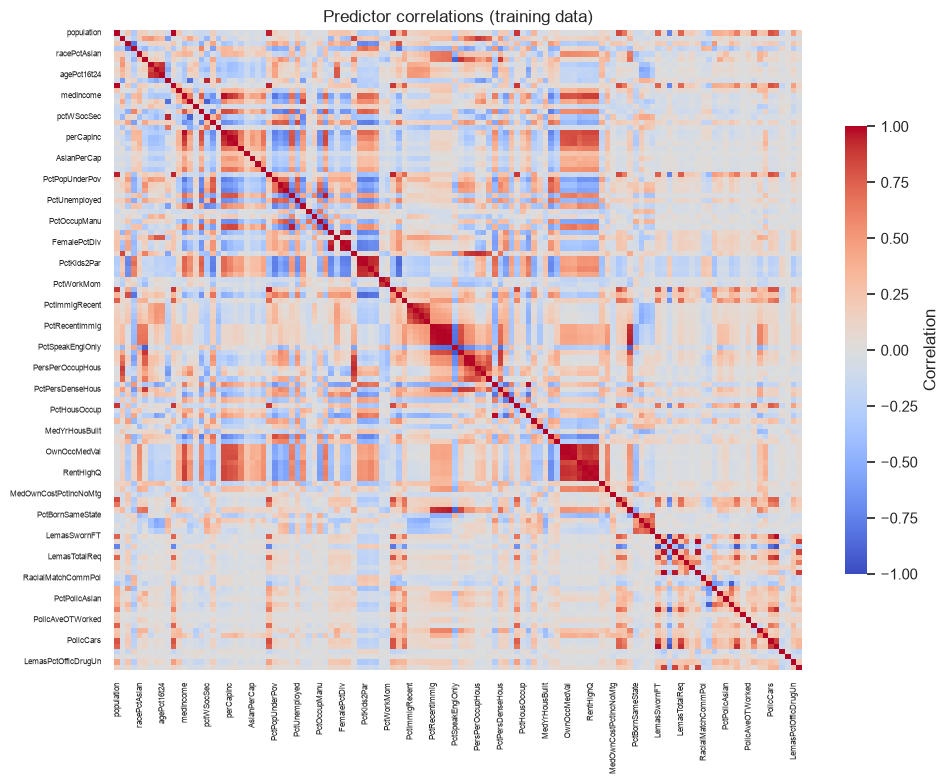

In [7]:
correlations = X_descriptive.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlations, cmap="coolwarm", vmin=-1, vmax=1, center=0, xticklabels=4, yticklabels=4, cbar_kws={"label": "Correlation", "shrink": 0.7})
plt.xticks(fontsize=6, rotation=90)
plt.yticks(fontsize=6, rotation=0)
plt.title("Predictor correlations (training data)")
plt.tight_layout()
plt.show()

### (d) Coefficient of variation

For each predictor, I calculate CV = sample standard deviation / mean on the imputed training data, using `ddof=1`. All predictor means are positive. The table shows all 122 features in three feature/CV pairs per row to save space.

In [8]:
feature_cv = (X_descriptive.std(ddof=1) / X_descriptive.mean()).sort_values(ascending=False)
cv_table = feature_cv.rename_axis("Feature").reset_index(name="CV")
blocks = [cv_table.iloc[start:start + 41].reset_index(drop=True).rename(columns={"Feature": f"Feature {i + 1}", "CV": f"CV {i + 1}"})
          for i, start in enumerate(range(0, len(cv_table), 41))]
display(pd.concat(blocks, axis=1).fillna(""))

,Feature 1,CV 1,Feature 2,CV 2,Feature 3,CV 3
0,PctPolicAsian,5.5271,PctLargHouseFam,0.7387,agePct12t21,0.3691
1,NumStreet,4.2929,pctWPubAsst,0.7062,PersPerOccupHous,0.3673
2,NumInShelters,3.4710,pctWFarmSelf,0.7019,pctWInvInc,0.3653
3,NumIlleg,3.0590,PctImmigRecent,0.6815,pctWSocSec,0.3607
4,NumImmig,2.9266,PctLess9thGrade,0.6805,FemalePctDiv,0.3604
5,LemasPctOfficDrugUn,2.5529,OtherPerCap,0.6733,householdsize,0.3558
6,NumUnderPov,2.3424,pctUrban,0.6433,PctEmploy,0.3515
7,LemasSwornFT,2.2480,RentLowQ,0.6397,PctPersOwnOccup,0.3492
8,population,2.2411,AsianPerCap,0.6149,pctWRetire,0.3454
9,numbUrban,2.0385,blackPerCap,0.5993,PolicPerPop,0.3443


### (e) Plots of the 11 highest-CV features

I select floor(sqrt(128)) = 11 predictors by CV. Scatter plots compare each predictor with the response; box plots show each predictor's spread and outliers. High CV means high relative variation, not statistical significance. The scatter plots can suggest associations, but cannot establish significance or account for correlated predictors.

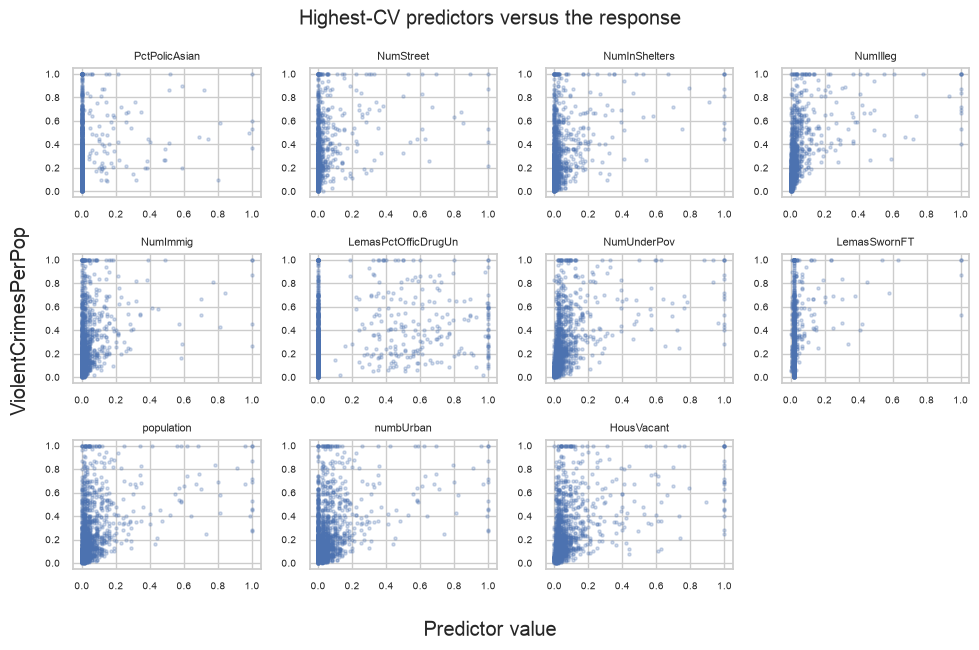

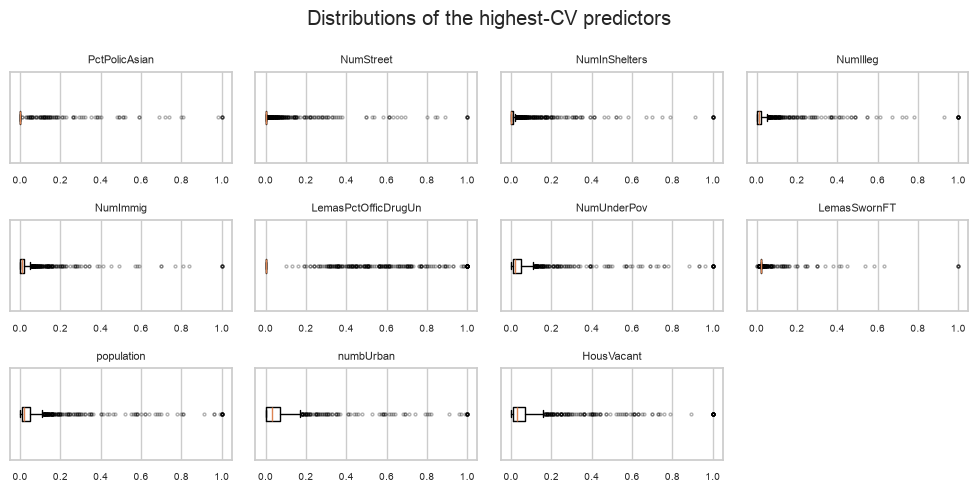

In [9]:
top_features = feature_cv.head(int(np.sqrt(128))).index
fig, axes = plt.subplots(3, 4, figsize=(10, 6.5))
for ax, feature in zip(axes.flat, top_features):
    ax.scatter(X_descriptive[feature], y_train, s = 5, alpha = 0.25)
    ax.set_title(feature, fontsize = 8)
    ax.tick_params(labelsize = 7)
axes.flat[-1].set_visible(False)
fig.supxlabel("Predictor value")
fig.supylabel("ViolentCrimesPerPop")
fig.suptitle("Highest-CV predictors versus the response")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 4, figsize = (10, 5))
for ax, feature in zip(axes.flat, top_features):
    ax.boxplot(X_descriptive[feature], orientation = "horizontal" , flierprops = {"markersize": 2, "alpha": 0.3})
    ax.set_title(feature, fontsize = 8)
    ax.set_yticks([])
    ax.tick_params(labelsize = 7)
axes.flat[-1].set_visible(False)
fig.suptitle("Distributions of the highest-CV predictors")
fig.tight_layout()
plt.show()

### (f) Ordinary least squares

I fit all 122 predictors, not just the 11 selected for plotting. The helper below records each model's test MSE. For tuned models, it selects settings using the same five training folds and then refits on all training rows.

In [10]:
def fit_and_report(name, model, parameters = None):
    if parameters is not None:
        model = GridSearchCV(model, parameters, cv = cv, scoring = "neg_mean_squared_error", error_score = "raise")
    model.fit(X_train, y_train)
    mse = mean_squared_error(y_test, model.predict(X_test))
    results.append({"Model": name, "Test MSE": mse})
    if parameters is not None:
        settings = ", ".join(f"{key.split('__')[-1]}= {value:.6g}" for key, value in model.best_params_.items())
        print(f"{name}: {settings}")
    print(f"{name}: test MSE = {mse:.6f}")
    return model

ols = fit_and_report("OLS", make_pipeline(SimpleImputer(strategy="median"),
                                         LinearRegression()))

OLS: test MSE = 0.017966


### (g) Ridge regression

I standardize predictors and choose the ridge penalty by CV over 41 values from 0.001 to 10,000. The printed `alpha` is the library's penalty parameter.

In [11]:
ridge = fit_and_report("Ridge", make_pipeline(SimpleImputer(strategy = "median"), StandardScaler(), Ridge()),
                       {"ridge__alpha": np.logspace(-3, 4, 41)})

Ridge: alpha= 118.85
Ridge: test MSE = 0.017380


### (h) LASSO, before and after standardization

I tune the penalty separately for each version over 41 values from 0.00001 to 0.1. The given predictors are normalized to [0, 1], but standardization additionally gives them mean zero and unit variance. Selected variables are those with nonzero fitted coefficients; the intercept is not included.

In [12]:
lasso_models, selected = {}, {}
for name, scaler in [("LASSO unscaled", "passthrough"), ("LASSO standardized", StandardScaler())]:
    pipeline = make_pipeline(SimpleImputer(strategy="median"), scaler, Lasso(max_iter=100000, tol=1e-5))
    fitted = fit_and_report(name, pipeline, {"lasso__alpha": np.logspace(-5, -1, 41)})
    lasso_models[name] = fitted
    coefficients = fitted.best_estimator_.named_steps["lasso"].coef_
    selected[name] = X_train.columns[coefficients != 0].tolist()
    print(f"Selected variables: {len(selected[name])}")

display(pd.DataFrame({name: pd.Series(variables) for name, variables in selected.items()}).fillna(""))

LASSO unscaled: alpha= 0.000125893
LASSO unscaled: test MSE = 0.017615
Selected variables: 74
LASSO standardized: alpha= 0.000630957
LASSO standardized: test MSE = 0.017722
Selected variables: 76


,LASSO unscaled,LASSO standardized
0,racepctblack,racepctblack
1,racePctAsian,racePctAsian
2,agePct12t21,agePct12t21
3,agePct12t29,agePct12t29
4,pctUrban,pctUrban
5,pctWWage,pctWWage
6,pctWFarmSelf,pctWFarmSelf
7,pctWInvInc,pctWInvInc
8,pctWSocSec,pctWSocSec
9,pctWPubAsst,pctWPubAsst


Unscaled LASSO has slightly lower test MSE here. Standardization changes how the penalty treats features with different spreads, but is not automatically better. Both variable lists are shown in full. The test set is not used to choose either penalty.

### (i) Principal component regression

I standardize predictors, apply PCA, and fit least squares to the component scores. CV compares every component count from 1 through 122. Both scaling and PCA are fitted inside each training fold.

In [13]:
pcr = fit_and_report("PCR", make_pipeline(SimpleImputer(strategy ="median"), StandardScaler(), PCA(svd_solver="full"), LinearRegression()),
                     {"pca__n_components": range(1, X_train.shape[1] + 1)})

PCR: n_components= 60
PCR: test MSE = 0.018350


### (j) L1-penalized boosting

I use XGBoost's tree booster and tune `reg_alpha` by CV. This is XGBoost's L1 penalty on leaf weights, not a separate LASSO regression fitted at each node. I fix 300 trees, depth 3, and learning rate 0.05, and set the L2 penalty to zero to focus on L1 regularization. [Parameter documentation](https://xgboost.readthedocs.io/en/stable/parameter.html).

In [14]:
boosting = fit_and_report("XGBoost L1", make_pipeline(SimpleImputer(strategy="median"),
    XGBRegressor(objective="reg:squarederror", booster="gbtree", n_estimators=300,
                 max_depth=3, learning_rate=0.05, reg_lambda=0, tree_method="hist",
                 n_jobs=1, random_state=SEED)),
    {"xgbregressor__reg_alpha": [0, 0.001, 0.01, 0.1, 1, 10, 100]})
with pd.option_context("display.precision", 6):
    display(pd.DataFrame(results).set_index("Model"))

XGBoost L1: reg_alpha= 1
XGBoost L1: test MSE = 0.016703


,Test MSE
Model,
OLS,0.017966
Ridge,0.017380
LASSO unscaled,0.017615
LASSO standardized,0.017722
PCR,0.018350
XGBoost L1,0.016703


XGBoost has the lowest test MSE in this comparison; ridge has the lowest among the linear models. These results use the same 499 held-out rows and do not imply that one method is always best. The test set is not used for additional tuning.